In [1]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append('/project/src')

from processing import grouped_barplot, grouped_lineplot

In [2]:
df = pd.read_csv("/project/data/hotel-booking-demand/hotel_bookings.csv")

In [3]:
df.dtypes

hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                                  str
country                               str
market_segment                        str
distribution_channel                  str
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                    str
assigned_room_type                    str
booking_changes                     int64
deposit_type                          str
agent                             

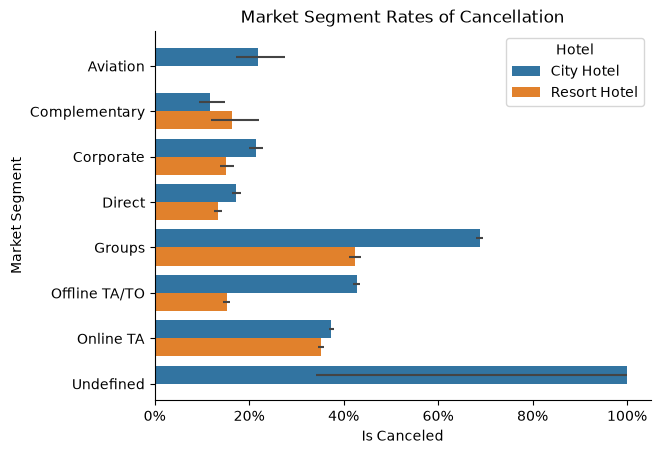

In [4]:
grouped_barplot(
    df,
    'market_segment',
    'is_canceled',
    'hotel',
    "Market Segment Rates of Cancellation"
)

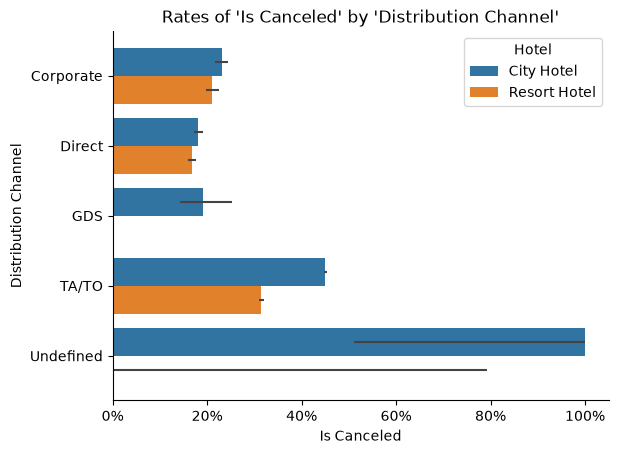

In [5]:
grouped_barplot(df, 'distribution_channel', 'is_canceled', 'hotel')

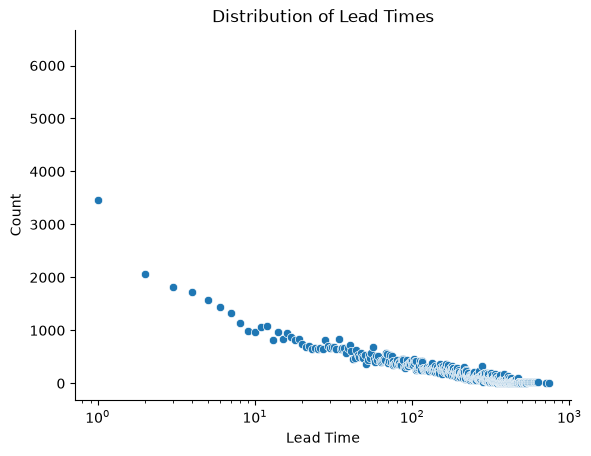

In [6]:
ax = sns.scatterplot(
    df['lead_time'].value_counts().sort_index().reset_index(),
    x = 'lead_time',
    y = 'count'
)
ax.set_xscale('log')
ax.set_title('Distribution of Lead Times')
ax.set_xlabel('Lead Time')
ax.set_ylabel('Count')
sns.despine(ax=ax)
plt.show()

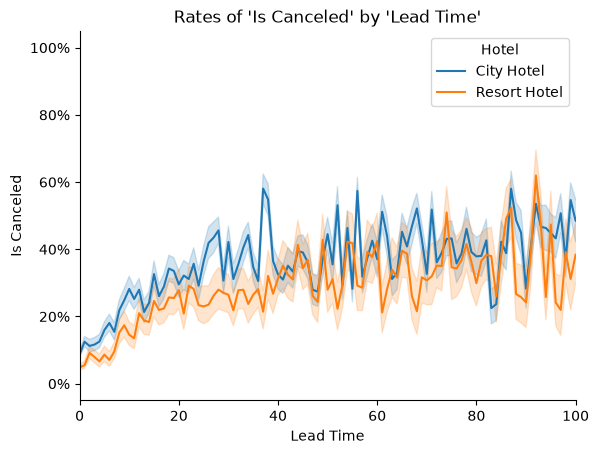

In [7]:
grouped_lineplot(df, 'lead_time', 'is_canceled', 'hotel', xlim=(0, 100))

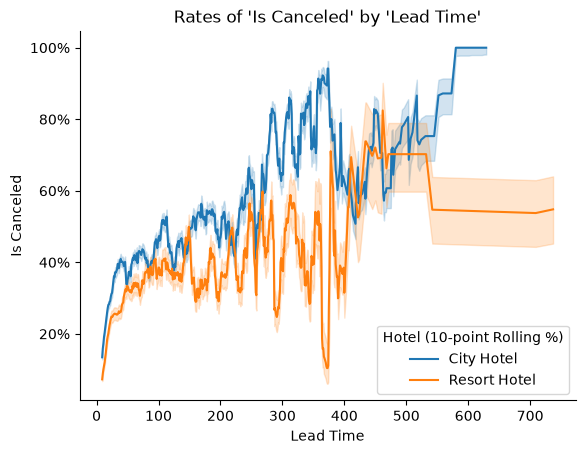

In [8]:
grouped_lineplot(df, 'lead_time', 'is_canceled', 'hotel', rolling_period=10)

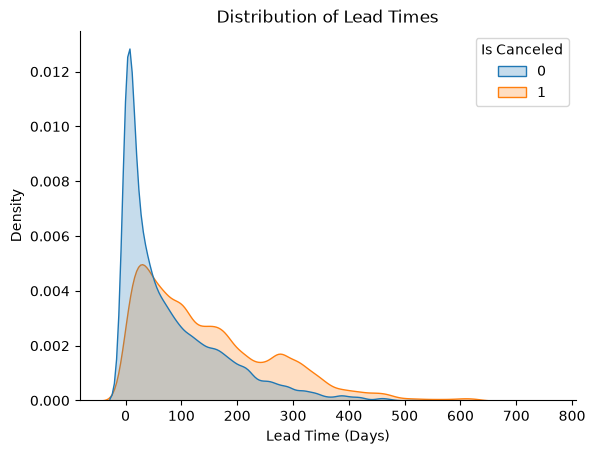

In [9]:
ax = sns.kdeplot(
    df,
    x='lead_time',
    hue='is_canceled',
    common_norm=False,
    fill=True
)
ax.set_title('Distribution of Lead Times')
ax.get_legend().set_title('Is Canceled')
ax.set_xlabel('Lead Time (Days)')
sns.despine(ax=ax)
plt.show()

In [11]:
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str)
    + '-'
    + df['arrival_date_month']
    + '-'
    + df['arrival_date_day_of_month'].astype(str),
    format='%Y-%B-%d'
)
df['arrival_month_and_day'] = pd.to_datetime(
    '2000-' + df['arrival_date'].dt.strftime('%m-%d'),
    format='%Y-%m-%d'
)

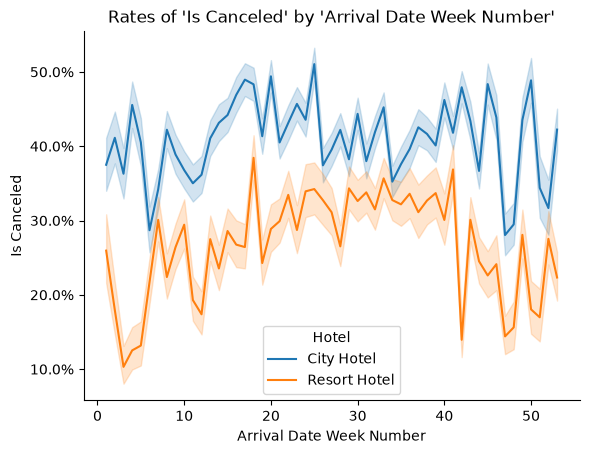

In [12]:
grouped_lineplot(df, 'arrival_date_week_number', 'is_canceled', 'hotel')

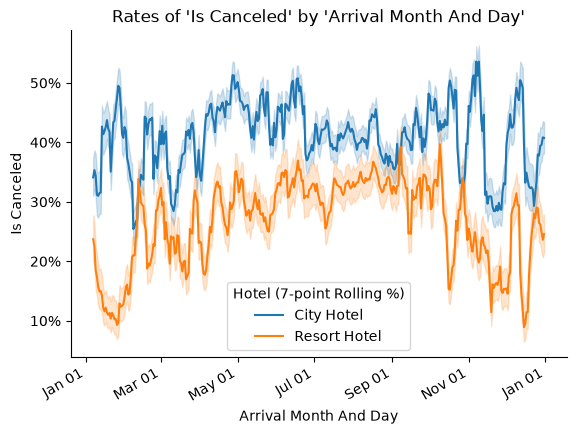

In [13]:
grouped_lineplot(df, 'arrival_month_and_day', 'is_canceled', 'hotel', rolling_period=7, remove_year=True)

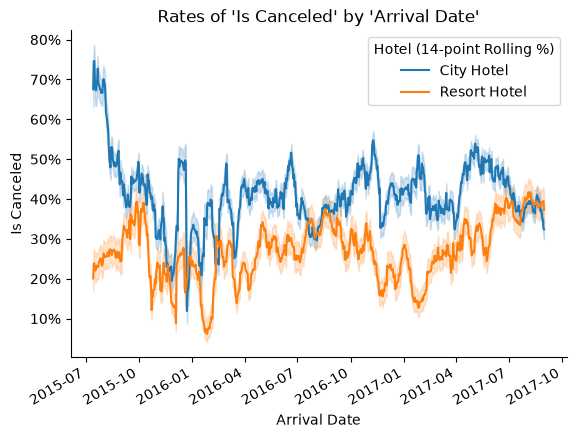

In [14]:
grouped_lineplot(df, 'arrival_date', 'is_canceled', 'hotel', rolling_period=14)

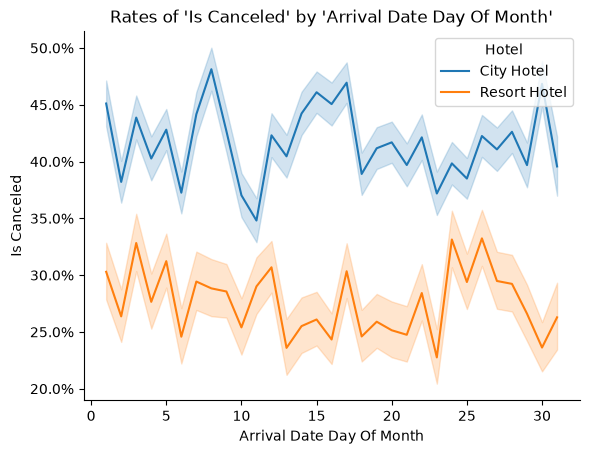

In [15]:
grouped_lineplot(df, 'arrival_date_day_of_month', 'is_canceled', 'hotel')